# Final comparison and trade-off discussion

## 1. Load results and build the table

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT_DIR = Path("./outputs")
FILES = [("modelA", "Model A"), ("modelB", "Model B"), ("mobilenetv2", "MobileNetV2"), ("shufflenetv2", "ShuffleNetV2")]

rows = {}
for tag, name in FILES:
    p = OUT_DIR / f"{tag}_results.json"
    if p.exists():
        r = json.load(open(p))
        rows[name] = {
            "Params": r["params"], "MACs (M)": r["macs"] / 1e6, "Size (KB)": r["size_kb"],
            "Size (MB)": r["size_kb"] / 1024, "Time/epoch (s)": r["time_per_epoch_s"],
            "Latency (ms)": r["latency_ms_cpu"], "Test acc (%)": 100 * r["test_acc"],
            "Macro prec (%)": 100 * r["macro_precision"], "Macro recall (%)": 100 * r["macro_recall"],
        }
    else:
        print("missing:", p)

df = pd.DataFrame(rows).T
disp = df.copy()
disp["Params"] = df["Params"].map("{:,.0f}".format)
for col in disp.columns[1:]:
    disp[col] = df[col].map("{:,.2f}".format)
disp

,Params,MACs (M),Size (KB),Size (MB),Time/epoch (s),Latency (ms),Test acc (%),Macro prec (%),Macro recall (%)
Model A,"914,122",60.69,"3,575.20",3.49,55.78,3.62,94.42,94.42,94.36
Model B,"67,179",11.80,286.80,0.28,601.20,5.87,94.32,94.28,94.20
MobileNetV2,"2,236,682",24.46,"8,972.90",8.76,184.42,15.02,97.68,97.61,97.59
ShuffleNetV2,"1,263,854",11.76,"5,103.10",4.98,128.55,23.20,97.48,97.46,97.35


## 2. Figures
Bar charts use a log scale where values span orders of magnitude. The last panel plots accuracy against compute, with bubble area proportional to parameter count: the closer to the top-left, the better the accuracy per unit of compute.

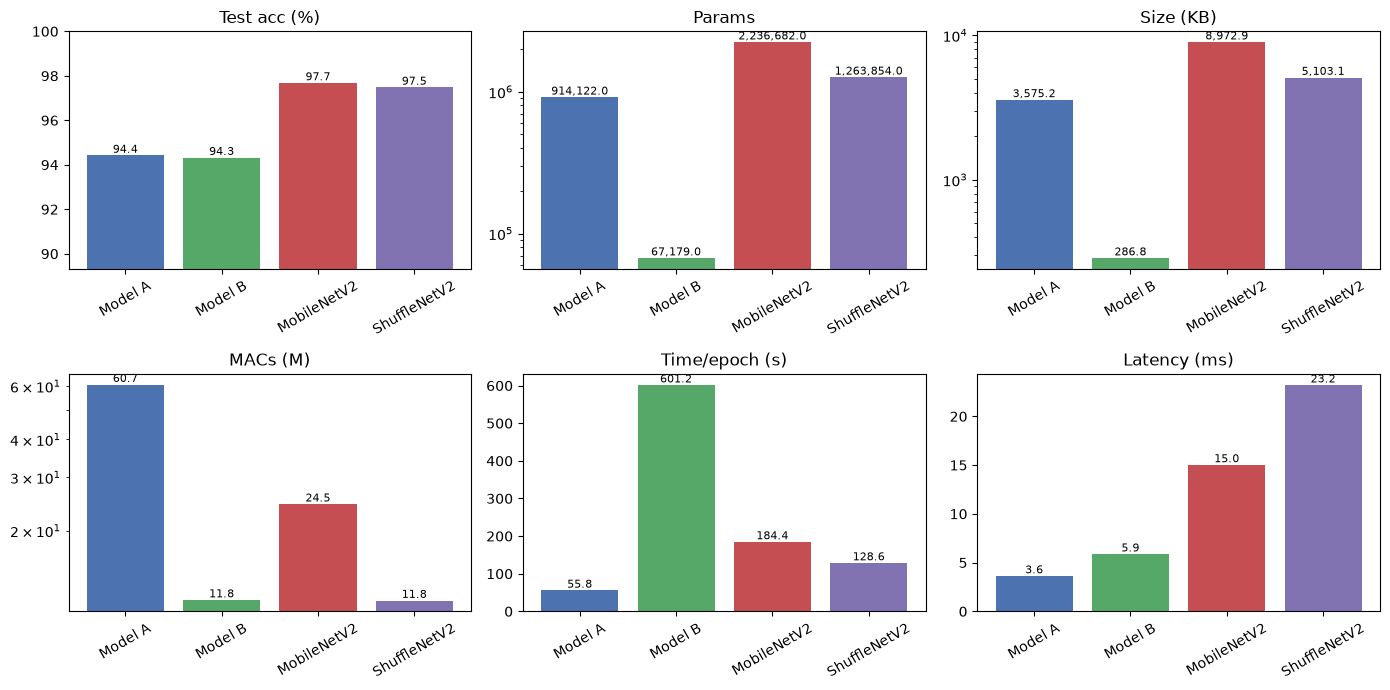

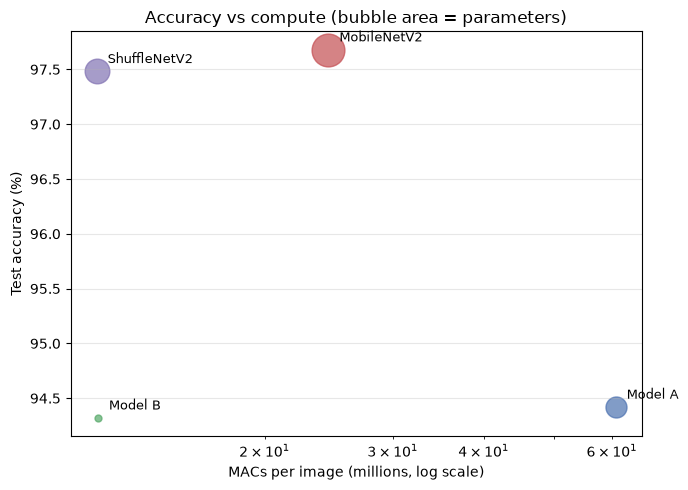

In [2]:
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"][:len(df)]
panels = [("Test acc (%)", False), ("Params", True), ("Size (KB)", True),
          ("MACs (M)", True), ("Time/epoch (s)", False), ("Latency (ms)", False)]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, logy) in zip(axes.ravel(), panels):
    ax.bar(df.index, df[col], color=colors)
    if logy:
        ax.set_yscale("log")
    if col == "Test acc (%)":
        ax.set_ylim(max(0, df[col].min() - 5), 100)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(df[col]):
        ax.text(i, v, f"{v:,.1f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "final_bars.png", dpi=150); plt.show()

plt.figure(figsize=(7, 5))
for (name, r), col in zip(df.iterrows(), colors):
    plt.scatter(r["MACs (M)"], r["Test acc (%)"], s=max(25, r["Params"] / 4000), color=col, alpha=0.7, label=name)
    plt.annotate(name, (r["MACs (M)"], r["Test acc (%)"]), textcoords="offset points", xytext=(8, 6), fontsize=9)
plt.xscale("log"); plt.xlabel("MACs per image (millions, log scale)"); plt.ylabel("Test accuracy (%)")
plt.title("Accuracy vs compute (bubble area = parameters)"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "final_tradeoff.png", dpi=150); plt.show()

## 3. Ratios relative to Model B (numbers for the discussion)

In [3]:
if "Model B" in df.index:
    B = df.loc["Model B"]
    for name in df.index:
        if name == "Model B":
            continue
        r = df.loc[name]
        print(f"{name:<13}: {r['Params']/B['Params']:6.1f}x params | {r['MACs (M)']/B['MACs (M)']:6.1f}x MACs | "
              f"{r['Size (KB)']/B['Size (KB)']:6.1f}x size | {r['Latency (ms)']/B['Latency (ms)']:5.2f}x latency | "
              f"accuracy {r['Test acc (%)'] - B['Test acc (%)']:+.2f} points vs Model B")
else:
    print("Model B results not found.")

Model A      :   13.6x params |    5.1x MACs |   12.5x size |  0.62x latency | accuracy +0.10 points vs Model B
MobileNetV2  :   33.3x params |    2.1x MACs |   31.3x size |  2.56x latency | accuracy +3.36 points vs Model B
ShuffleNetV2 :   18.8x params |    1.0x MACs |   17.8x size |  3.95x latency | accuracy +3.16 points vs Model B


## 4. Ready-to-paste LaTeX table

In [4]:
def latex_table(df):
    cols = ["Params", "MACs (M)", "Size", "Time/ep (s)", "Latency (ms)", "Acc (\\%)", "Prec (\\%)", "Rec (\\%)"]
    lines = [r"\begin{table}[h]", r"\centering",
             r"\caption{Comparison of the custom and fine-tuned lightweight models on the test set.}",
             r"\label{tab:comparison}",
             r"\begin{tabular}{l" + "r" * len(cols) + "}", r"\hline",
             "Model & " + " & ".join(cols) + r" \\", r"\hline"]
    for name, r in df.iterrows():
        size = "{:.0f} KB".format(r["Size (KB)"]) if r["Size (KB)"] < 1024 else "{:.2f} MB".format(r["Size (MB)"])
        lines.append("{} & {:,.0f} & {:.1f} & {} & {:.1f} & {:.2f} & {:.2f} & {:.2f} & {:.2f}".format(
            name, r["Params"], r["MACs (M)"], size, r["Time/epoch (s)"], r["Latency (ms)"],
            r["Test acc (%)"], r["Macro prec (%)"], r["Macro recall (%)"]) + r" \\")
    lines += [r"\hline", r"\end{tabular}", r"\end{table}"]
    return "\n".join(lines)

tex = latex_table(df)
(OUT_DIR / "comparison_table.tex").write_text(tex)
print(tex)

\begin{table}[h]
\centering
\caption{Comparison of the custom and fine-tuned lightweight models on the test set.}
\label{tab:comparison}
\begin{tabular}{lrrrrrrrr}
\hline
Model & Params & MACs (M) & Size & Time/ep (s) & Latency (ms) & Acc (\%) & Prec (\%) & Rec (\%) \\
\hline
Model A & 914,122 & 60.7 & 3.49 MB & 55.8 & 3.62 & 94.42 & 94.42 & 94.36 \\
Model B & 67,179 & 11.8 & 287 KB & 601.2 & 5.87 & 94.32 & 94.28 & 94.20 \\
MobileNetV2 & 2,236,682 & 24.5 & 8.76 MB & 184.4 & 15.02 & 97.68 & 97.61 & 97.59 \\
ShuffleNetV2 & 1,263,854 & 11.8 & 4.98 MB & 128.6 & 23.20 & 97.48 & 97.46 & 97.35 \\
\hline
\end{tabular}
\end{table}


## 5. Discussion scaffold for Part 6

**Accuracy** - Gap between Model B and the two fine-tuned networks (Section 3). Is it a few points or many? Which classes does Model B confuse that the pretrained networks do not (compare confusion matrices)? Pretrained features come from 1.2 M ImageNet images, so part of their advantage is *data* the custom model never saw, not just architecture.

**Memory footprint** - Model B is 67,179 parameters (about 0.26 MB of float32 weights), so it fits in microcontroller-class flash/RAM and could shrink about 4x more with int8 quantisation. MobileNetV2 and ShuffleNetV2 are in the MB range: fine for a Raspberry Pi, a stretch for a microcontroller. Quote the size ratios.

**Computational cost** - Compare MACs *and* measured latency. If latency ratios are much smaller than MAC ratios, explain why (depthwise convolutions are memory-bound; ShuffleNetV2's design argument about memory access cost). Note that time per epoch also reflects training, not only inference.

**Custom sub-100k model from scratch - advantages:** full control of the memory/compute budget, tiny deployable size, no dependence on pretrained weights or licences, architecture tailored to the task and input size, easy to quantise. **Limitations:** needs enough labelled data, more design/tuning effort, lower accuracy ceiling, no benefit from large-scale pretraining.

**Pretrained lightweight model - advantages:** strong accuracy quickly (converges in few epochs), robust features, proven architecture, available tooling for deployment. **Limitations:** a fixed, larger footprint you cannot shrink to an arbitrary budget, the 64x64 input is far from its 224x224 pretraining resolution, more compute per image, and ImageNet features may transfer imperfectly to satellite imagery.

**Conclusion template:** pick the model that meets the deployment constraint first (memory, then latency), then maximise accuracy within it. State which model you would deploy for (a) a microcontroller and (b) a Raspberry Pi, and justify each with your numbers.